In [6]:
!pip install xgboost
import xgboost as xgb
from sklearn.model_selection import train_test_split

In [2]:
import pandas as pd
import numpy as np

# 1. Load the final PLFS data
df = pd.read_csv("/Users/abhishek/Desktop/world-bank-indicators-project/final_plfs_with_exposure.csv")

# 2. Bring education back in
edu22 = pd.read_csv("/Users/abhishek/Desktop/world-bank-indicators-project/PLFS_2022/cperv1.csv", usecols=['b4q8_cperv1'])['b4q8_cperv1']
edu23 = pd.read_csv("/Users/abhishek/Desktop/world-bank-indicators-project/PLFS_2023/cperv1.csv", usecols=['b4q8_cperv1'])['b4q8_cperv1']
edu24 = pd.read_csv("/Users/abhishek/Desktop/world-bank-indicators-project/PLFS_2024/cperv1.csv", usecols=['General_Education_Level'])['General_Education_Level']
df['Education'] = pd.concat([edu22, edu23, edu24], ignore_index=True)

# 3. Filter to our wage sample (working age, salaried, major states)
df_wage_clean = df[(df['Age'] >= 15) & (df['Age'] <= 59) & (df['CWS_Earnings_Salaried'] > 0)].copy()
state_counts = df_wage_clean[df_wage_clean['Sex'] == 2].groupby('State_UT_Code').size()
big_states = state_counts[state_counts >= 100].index
df_wage_clean = df_wage_clean[df_wage_clean['State_UT_Code'].isin(big_states)].copy()

# 4. Re-create variables
df_wage_clean['Female'] = (df_wage_clean['Sex'] == 2).astype(int)
df_wage_clean['Log_Wage'] = np.log(df_wage_clean['CWS_Earnings_Salaried'])

print(f"Data ready! {len(df_wage_clean):,} rows.")

Data ready! 131,834 rows.


In [3]:
# Define our features (X) and target (y)
features = ['Routine_Intensity', 'Female', 'Age', 'Education', 'State_UT_Code', 'Sector', 'Year']
X = df_wage_clean[features]
y = df_wage_clean['Log_Wage']

In [4]:
from sklearn.metrics import r2_score

In [7]:
# 2. Split into 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train the XGBoost model
model = xgb.XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42)
model.fit(X_train, y_train)

# 4. Check accuracy
preds = model.predict(X_test)
r2 = r2_score(y_test, preds)
print(f"Out-of-Sample R-squared: {r2:.4f}")

Out-of-Sample R-squared: 0.4568


In [9]:
!pip install shap


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 3.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [shap]━━━━━━ 1/2 [shap]


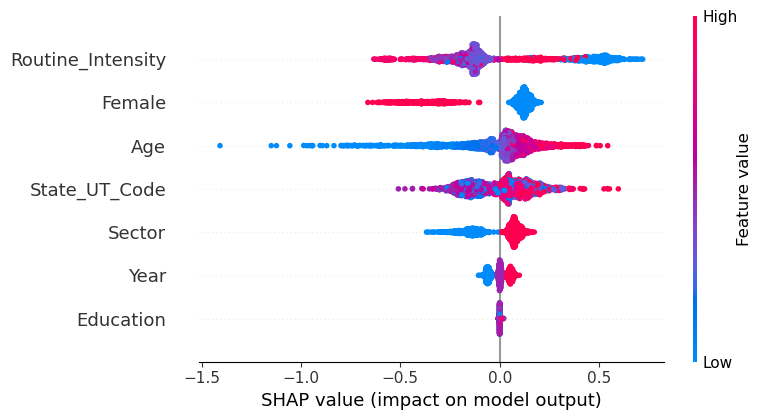

In [10]:
import shap
import matplotlib.pyplot as plt

# 1. Create the SHAP explainer
explainer = shap.TreeExplainer(model)

# 2. Calculate SHAP values for a sample of 2,000 people (to make it fast)
X_sample = X_test.sample(2000, random_state=42)
shap_values = explainer.shap_values(X_sample)

# 3. Plot the summary
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample)


SHAP plot saved!


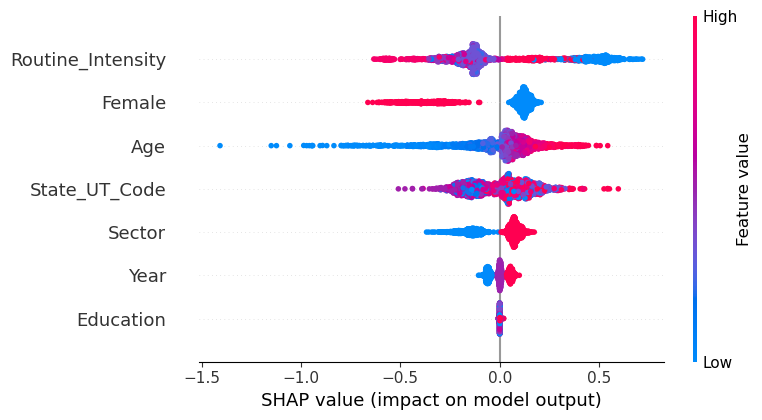

In [12]:
# Save the SHAP plot to your outputs folder
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample, show=False)
plt.savefig("/Users/abhishek/Desktop/world-bank-indicators-project/notebooks/03_india_labour/outputs/figures/task8_shap_summary.png", bbox_inches='tight', dpi=300)
print("SHAP plot saved!")

/var/folders/6v/s9_yhnl534n43tphxkf70pxh0000gn/T/ipykernel_39331/1938295550.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  state_summary = df_wage_clean.groupby('State_UT_Code').apply(
/var/folders/6v/s9_yhnl534n43tphxkf70pxh0000gn/T/ipykernel_39331/1938295550.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_summary.sort_values('Mean_Exposure', ascending=False).head(15),


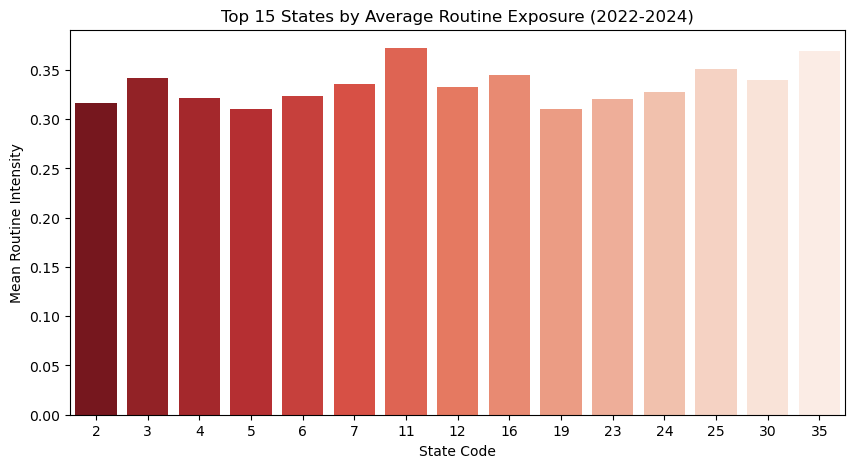

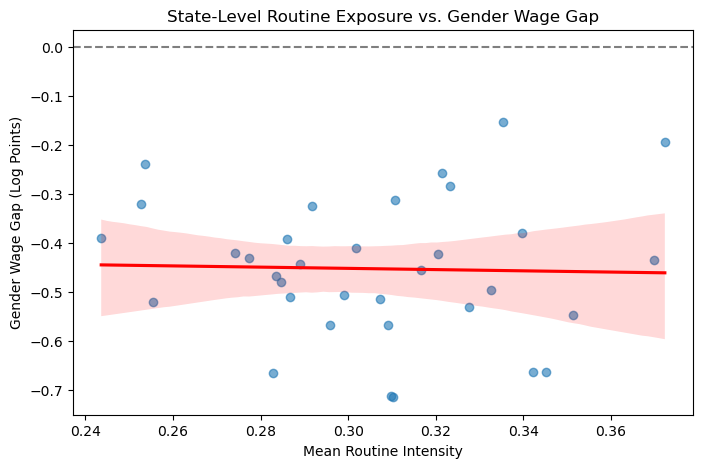

In [13]:
import seaborn as sns

# Create a state-level summary (weighted by PLFS multiplier)
state_summary = df_wage_clean.groupby('State_UT_Code').apply(
    lambda x: pd.Series({
        'Mean_Exposure': np.average(x['Routine_Intensity'], weights=x['Subsample_Multiplier']),
        'Gender_Wage_Gap': x[x['Female']==1]['Log_Wage'].mean() - x[x['Female']==0]['Log_Wage'].mean()
    })
).reset_index()

# Chart 1: Bar Chart of Routine Exposure by State
plt.figure(figsize=(10, 5))
sns.barplot(data=state_summary.sort_values('Mean_Exposure', ascending=False).head(15), 
            x='State_UT_Code', y='Mean_Exposure', palette='Reds_r')
plt.title('Top 15 States by Average Routine Exposure (2022-2024)')
plt.xlabel('State Code')
plt.ylabel('Mean Routine Intensity')
plt.savefig("outputs/figures/task5_exposure_by_state.png", bbox_inches='tight', dpi=300)
plt.show()

# Chart 2: Scatter plot of Exposure vs Gender Wage Gap
plt.figure(figsize=(8, 5))
sns.regplot(data=state_summary, x='Mean_Exposure', y='Gender_Wage_Gap', 
            scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
plt.title('State-Level Routine Exposure vs. Gender Wage Gap')
plt.xlabel('Mean Routine Intensity')
plt.ylabel('Gender Wage Gap (Log Points)')
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.savefig("outputs/figures/task5_exposure_vs_gap.png", bbox_inches='tight', dpi=300)
plt.show()